In [2]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance
from sklearn.utils import shuffle
from tensorflow.keras.preprocessing.image import load_img
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dropout, Dense
from tensorflow.keras.optimizers import Adam


2025-04-14 12:08:46.446505: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1744632526.650330      31 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1744632526.707591      31 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [10]:
train_dir = '/kaggle/input/braintumor/Training/'
val_dir = '/kaggle/input/braintumor/Testing/'

train_paths = []
train_labels = []

for label in os.listdir(train_dir):
    label_path = os.path.join(train_dir, label)
    if os.path.isdir(label_path):
        for image in os.listdir(label_path):
            train_paths.append(os.path.join(label_path, image))
            train_labels.append(label)

train_paths, train_labels = shuffle(train_paths, train_labels)

val_paths = []
val_labels = []

for label in os.listdir(val_dir):
    label_path = os.path.join(val_dir, label)
    if os.path.isdir(label_path):
        for image in os.listdir(label_path):
            val_paths.append(os.path.join(label_path, image))
            val_labels.append(label)

val_paths, val_labels = shuffle(val_paths, val_labels)


In [11]:
def augment_image(image):
    image = Image.fromarray(np.uint8(image))
    image = ImageEnhance.Brightness(image).enhance(random.uniform(0.8, 1.2))
    image = ImageEnhance.Contrast(image).enhance(random.uniform(0.8, 1.2))
    image = np.array(image) / 255.0
    return image


In [12]:
IMAGE_SIZE = 128

def open_images(paths):
    images = []
    for path in paths:
        image = load_img(path, target_size=(IMAGE_SIZE, IMAGE_SIZE))
        image = np.array(image)
        image = augment_image(image)
        images.append(image)
    return np.array(images)


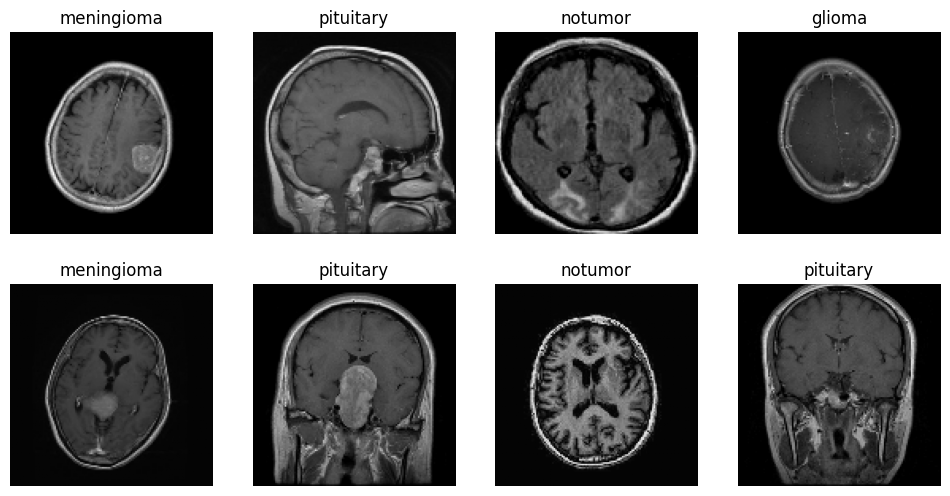

In [13]:
images = open_images(train_paths[50:58])
labels = train_labels[50:58]

fig = plt.figure(figsize=(12, 6))
for i in range(len(images)):
    fig.add_subplot(2, 4, i + 1)
    plt.axis('off')
    plt.title(labels[i])
    plt.imshow(images[i])
plt.rcParams.update({'font.size': 20})
plt.show()


In [14]:
unique_labels = os.listdir(train_dir)

def encode_label(labels):
    return np.array([unique_labels.index(x) for x in labels])

def decode_label(labels):
    return np.array([unique_labels[x] for x in labels])


In [15]:
def datagen(paths, labels, batch_size=12, epochs=1):
    for _ in range(epochs):
        for x in range(0, len(paths), batch_size):
            batch_paths = paths[x:x + batch_size]
            batch_images = open_images(batch_paths)
            batch_labels = encode_label(labels[x:x + batch_size])
            yield batch_images, batch_labels


In [17]:
base_model = VGG16(input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3), include_top=False, weights='imagenet')

for layer in base_model.layers:
    layer.trainable = False

for layer in base_model.layers[-4:-1]:
    layer.trainable = True

model = Sequential([
    Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3)),
    base_model,
    Flatten(),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(len(unique_labels), activation='softmax')
])

model.summary()


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)                   │ (None, 4, 4, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 8192)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 8192)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       1,048,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 4)                   │             516 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 15,763,908 (60.13 MB)

 Trainable params: 8,128,644 (31.01 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

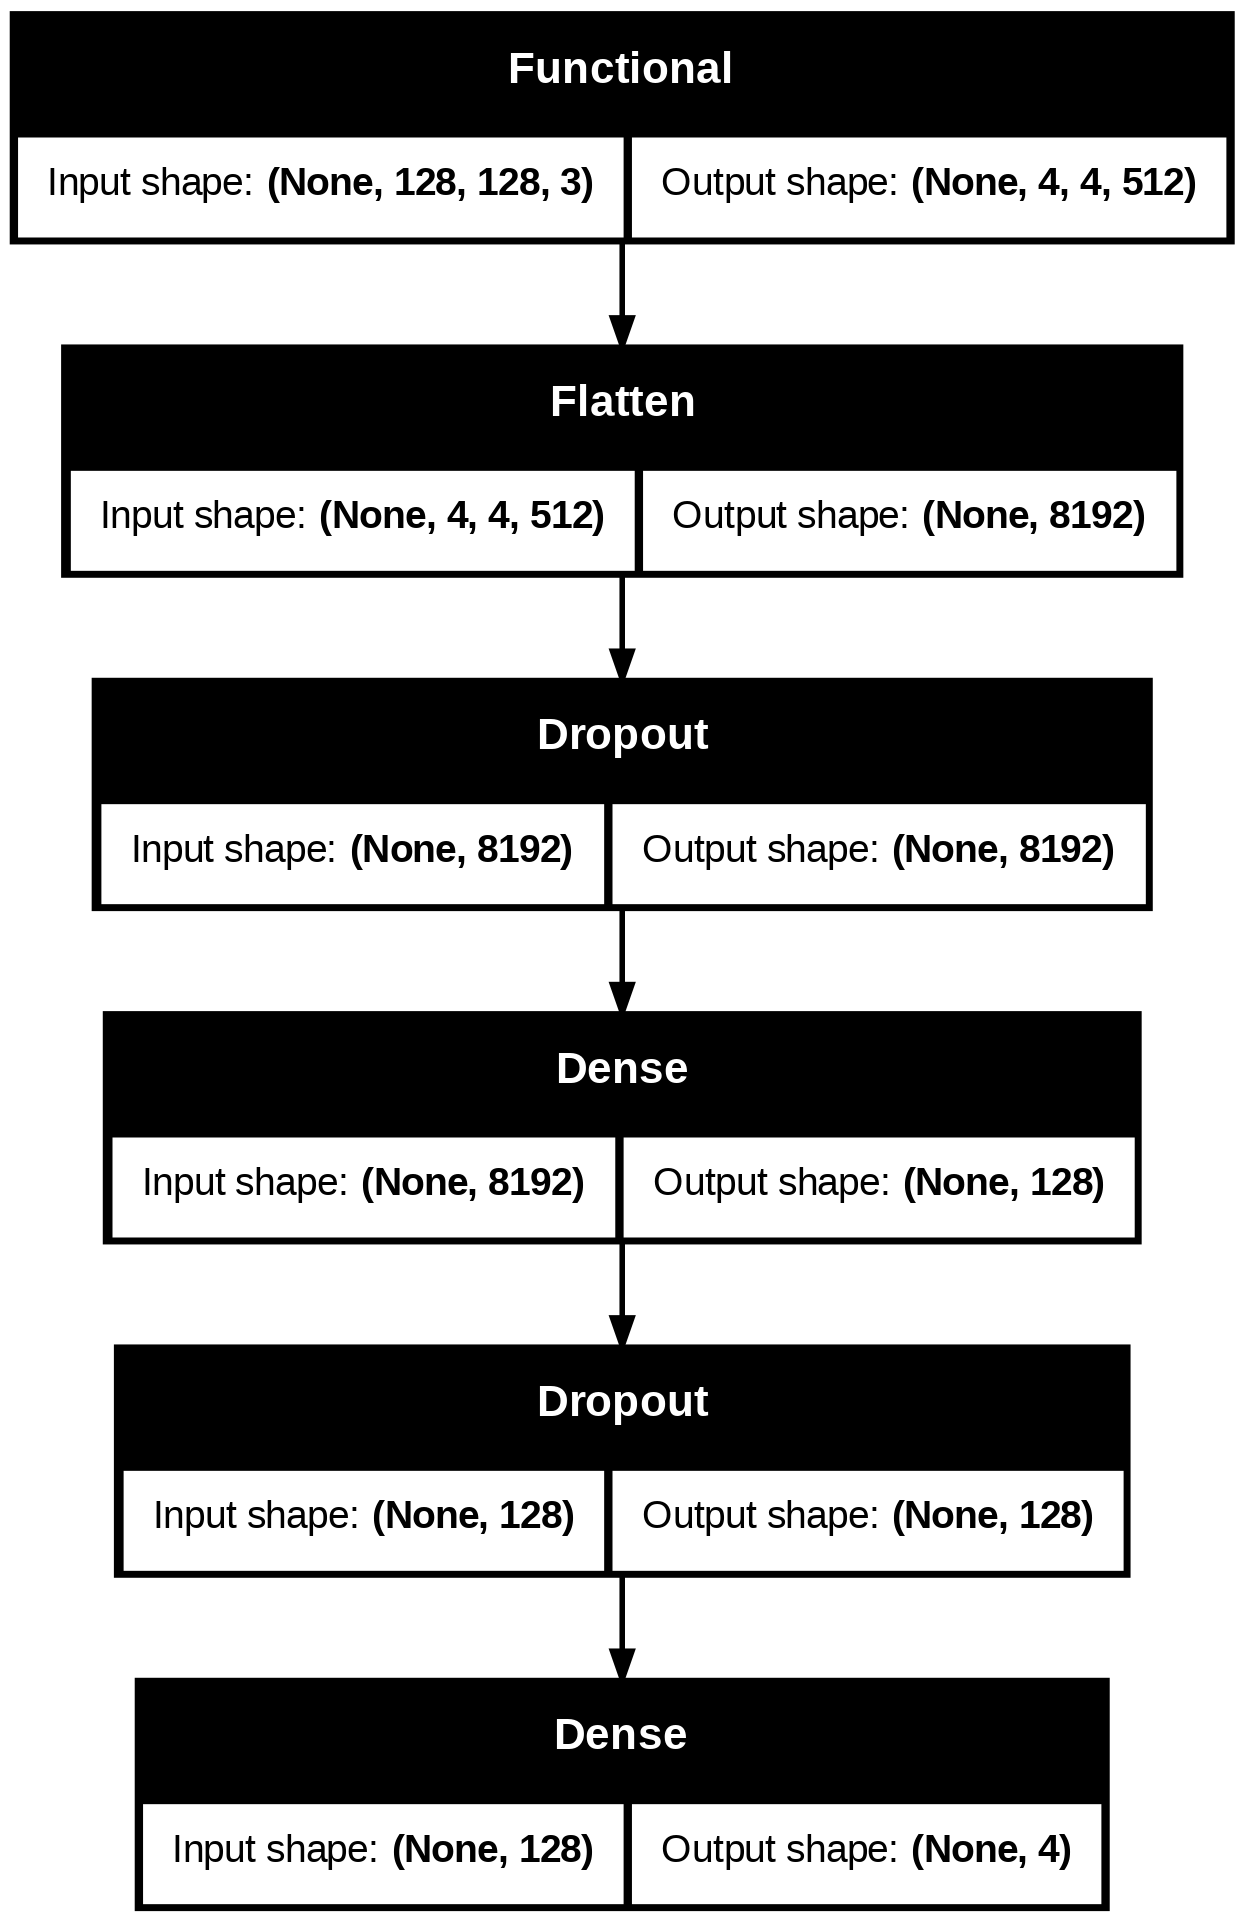

In [18]:
from tensorflow.keras.utils import plot_model

# Plot the model architecture to a PNG image and display shape info
plot_model(model, show_shapes=True, to_file='model_plot.png')


In [19]:
model.compile(optimizer=Adam(learning_rate=0.0001),
             loss='sparse_categorical_crossentropy',
             metrics=['sparse_categorical_accuracy'])

In [20]:
model.compile(optimizer=Adam(learning_rate=0.0001),
             loss='sparse_categorical_crossentropy',
             metrics=['sparse_categorical_accuracy'])

Epoch 1/10


I0000 00:00:1744632608.753140      96 service.cc:148] XLA service 0x7a09b4011540 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1744632608.754024      96 service.cc:156]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1744632609.153138      96 cuda_dnn.cc:529] Loaded cuDNN version 90300


  3/285 ━━━━━━━━━━━━━━━━━━━━ 19s 68ms/step - loss: 1.7033 - sparse_categorical_accuracy: 0.2500

I0000 00:00:1744632614.002715      96 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


285/285 ━━━━━━━━━━━━━━━━━━━━ 44s 126ms/step - loss: 0.6668 - sparse_categorical_accuracy: 0.7421
Epoch 2/10
285/285 ━━━━━━━━━━━━━━━━━━━━ 19s 55ms/step - loss: 0.2385 - sparse_categorical_accuracy: 0.9128
Epoch 3/10
285/285 ━━━━━━━━━━━━━━━━━━━━ 15s 53ms/step - loss: 0.1640 - sparse_categorical_accuracy: 0.9368
Epoch 4/10
285/285 ━━━━━━━━━━━━━━━━━━━━ 15s 54ms/step - loss: 0.1249 - sparse_categorical_accuracy: 0.9531
Epoch 5/10
285/285 ━━━━━━━━━━━━━━━━━━━━ 16s 55ms/step - loss: 0.0893 - sparse_categorical_accuracy: 0.9683
Epoch 6/10
285/285 ━━━━━━━━━━━━━━━━━━━━ 16s 55ms/step - loss: 0.0769 - sparse_categorical_accuracy: 0.9721
Epoch 7/10
285/285 ━━━━━━━━━━━━━━━━━━━━ 15s 53ms/step - loss: 0.0540 - sparse_categorical_accuracy: 0.9801
Epoch 8/10
285/285 ━━━━━━━━━━━━━━━━━━━━ 15s 54ms/step - loss: 0.0367 - sparse_categorical_accuracy: 0.9878
Epoch 9/10
285/285 ━━━━━━━━━━━━━━━━━━━━ 16s 55ms/step - loss: 0.0265 - sparse_categorical_accuracy: 0.9920
Epoch 10/10
285/285 ━━━━━━━━━━━━━━━━━━━━ 15s 54

Communication Round 1/3
Selected client indices based on importance scores: [4 5 6 8 2]
Global model updated.
Accuracy after round 1: 0.9802

Communication Round 2/3
Selected client indices based on importance scores: [2 4 7 5 8]
Global model updated.
Accuracy after round 2: 0.9817

Communication Round 3/3
Selected client indices based on importance scores: [8 7 1 6 3]
Global model updated.
Accuracy after round 3: 0.9802



66it [00:08,  8.00it/s]                        


Global model saved as 'my_model.h5'.


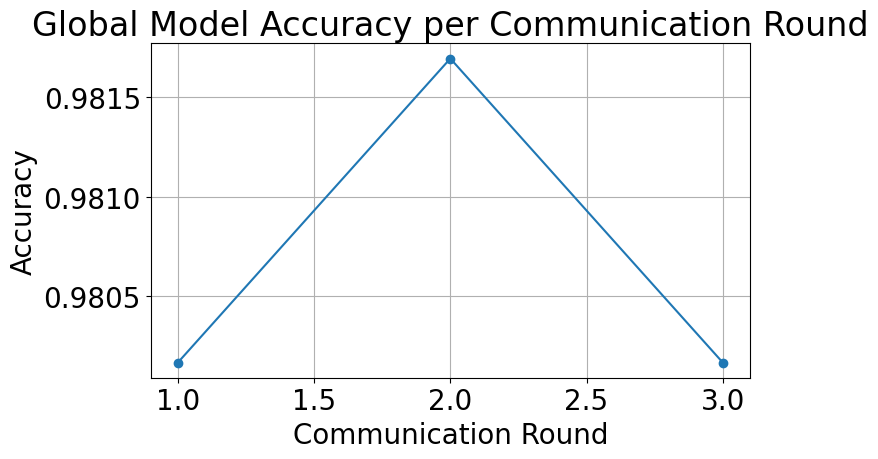

In [21]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.optimizers import Adam
from tqdm import tqdm  # For progress display

# Federated learning settings
NUM_CLIENTS = 10
NUM_ROUNDS = 3
CLIENT_SELECTION_RATIO = 0.5
alpha = 0.1

# NOTE: Ensure these are already defined:
# train_paths, train_labels, test_paths, test_labels
# datagen, decode_label, batch_size, epochs
# model (your global model)

# 1. Split the training data among clients
clients = []
for i in range(NUM_CLIENTS):
    start = i * (len(train_paths) // NUM_CLIENTS)
    end = (i + 1) * (len(train_paths) // NUM_CLIENTS)
    client_data = train_paths[start:end]
    client_labels = train_labels[start:end]
    clients.append((client_data, client_labels))

# Initialize global model
global_model = model

# Accuracy tracking
accuracy_per_round = []

# 2. Federated Learning Loop using AdaFL
for round_num in range(NUM_ROUNDS):
    print(f"Communication Round {round_num+1}/{NUM_ROUNDS}")
    
    local_weights_list = []
    local_losses = []
    client_sample_counts = []

    # Local training
    for i, (client_data, client_labels) in enumerate(clients):
        client_model = tf.keras.models.clone_model(global_model)
        client_model.set_weights(global_model.get_weights())

        client_model.compile(
            optimizer=Adam(learning_rate=0.0001),
            loss='sparse_categorical_crossentropy',
            metrics=['sparse_categorical_accuracy']
        )

        steps_per_epoch = max(1, len(client_data) // 20)

        history = client_model.fit(
            datagen(client_data, client_labels, batch_size=batch_size, epochs=epochs),
            epochs=5,
            steps_per_epoch=steps_per_epoch,
            verbose=0
        )

        final_loss = history.history['loss'][-1]
        local_weights_list.append(client_model.get_weights())
        local_losses.append(final_loss)
        client_sample_counts.append(len(client_data))

    # Importance scores
    total_samples = np.sum(client_sample_counts)
    importance_scores = []
    for i in range(NUM_CLIENTS):
        importance = (client_sample_counts[i] * np.exp(-alpha * local_losses[i])) / total_samples
        importance_scores.append(importance)

    importance_scores_arr = np.array(importance_scores)

    # Select top-m clients
    m = max(int(NUM_CLIENTS * CLIENT_SELECTION_RATIO), 1)
    selected_indices = np.argsort(importance_scores_arr)[-m:]
    print("Selected client indices based on importance scores:", selected_indices)

    # Aggregation coefficients
    total_importance_selected = np.sum([importance_scores[i] for i in selected_indices])
    delta = {i: importance_scores[i] / total_importance_selected for i in selected_indices}

    # Adaptive aggregation
    new_global_weights = []
    num_layers = len(global_model.get_weights())
    for layer_index in range(num_layers):
        weighted_sum = np.zeros_like(global_model.get_weights()[layer_index])
        for i in selected_indices:
            weighted_sum += delta[i] * local_weights_list[i][layer_index]
        new_global_weights.append(weighted_sum)

    global_model.set_weights(new_global_weights)
    print("Global model updated.")

    # Accuracy evaluation after round
    correct_preds = 0
    total_preds = 0
    val_steps = int(len(val_paths) / batch_size)

    for x, y in datagen(val_paths, val_labels, batch_size=batch_size, epochs=1):
        preds = global_model.predict(x, verbose=0)
        preds = np.argmax(preds, axis=-1)
        y = np.squeeze(y)

        correct_preds += np.sum(preds == y)
        total_preds += len(y)

        if total_preds >= len(val_paths):
            break

    accuracy = correct_preds / total_preds
    accuracy_per_round.append(accuracy)
    print(f"Accuracy after round {round_num+1}: {accuracy:.4f}\n")

# Final evaluation on full test set (optional)
y_pred = []
y_true = []
steps = int(len(val_paths) / batch_size)

for x, y in tqdm(datagen(val_paths, val_labels, batch_size=batch_size, epochs=1), total=steps):
    pred = global_model.predict(x, verbose=0)
    pred = np.argmax(pred, axis=-1)
    y_pred.extend(decode_label(pred))
    y_true.extend(decode_label(y))

# Optional: Evaluate accuracy using sklearn
# from sklearn.metrics import accuracy_score
# print("Test accuracy:", accuracy_score(y_true, y_pred))

# Save model
global_model.save('my_model.h5')
print("Global model saved as 'my_model.h5'.")

# Plot accuracy
plt.figure(figsize=(8, 5))
plt.plot(range(1, NUM_ROUNDS + 1), accuracy_per_round, marker='o', linestyle='-')
plt.title('Global Model Accuracy per Communication Round')
plt.xlabel('Communication Round')
plt.ylabel('Accuracy')
plt.grid(True)
plt.tight_layout()
plt.show()


In [23]:
from sklearn.metrics import classification_report
print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

      glioma       0.98      0.95      0.97       300
  meningioma       0.95      0.97      0.96       306
     notumor       1.00      1.00      1.00       405
   pituitary       0.99      0.99      0.99       300

    accuracy                           0.98      1311
   macro avg       0.98      0.98      0.98      1311
weighted avg       0.98      0.98      0.98      1311



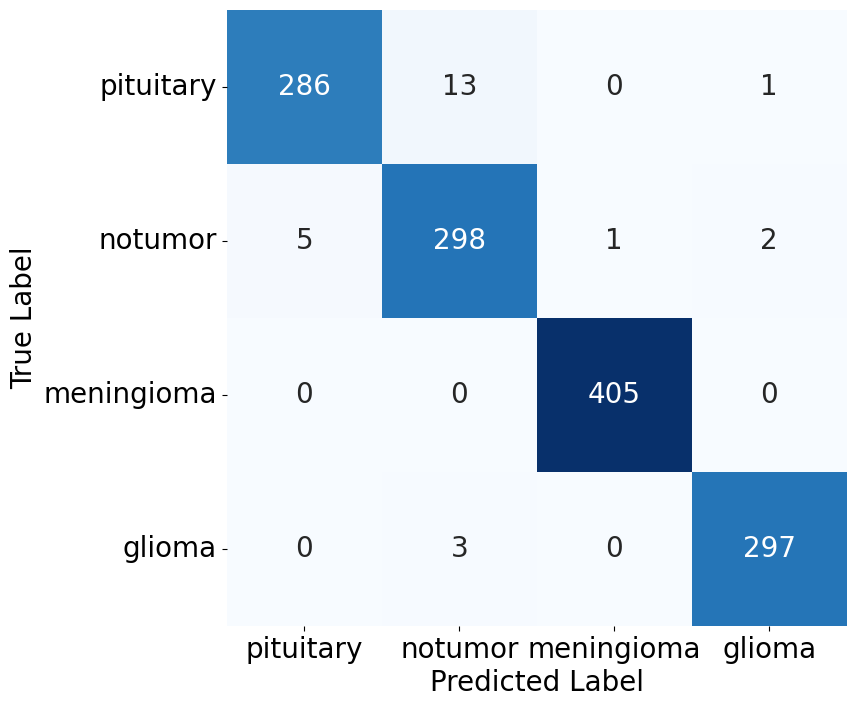

In [24]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np




cm = confusion_matrix(y_true, y_pred)

# Define the font size
font_size = 20

# Plot the confusion matrix
plt.figure(figsize=(8,8))
sns.heatmap(cm, annot=True, cmap="Blues", fmt="d", xticklabels=unique_labels, yticklabels=unique_labels, annot_kws={"fontsize": font_size}, cbar=False)
plt.xlabel("Predicted Label", fontsize=font_size)
plt.ylabel("True Label", fontsize=font_size)
plt.xticks(fontsize=font_size)
plt.yticks(fontsize=font_size, rotation=0)
plt.show()

